# Лабораторна робота № 7. Основи глибинного навчання у задачах машинного зору

## Індивідуальне завдання — Варіант 4

**Завдання:** розробити систему розпізнавання котів і собак із використанням відповідного набору зображень. Дослідити вплив Dropout, аугментації та регуляризації на здатність моделі узагальнювати дані.






## 1. Підготовка програмного середовища

In [2]:
import os
import time
import json
import random
import zipfile
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split

# Фіксуємо початковий стан генераторів випадкових чисел для відтворюваності
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE


def cv2_imread(path):
    # Читання зображення OpenCV з підтримкою кирилиці у шляху (на Windows cv2.imread її не підтримує)
    try:
        data = np.fromfile(path, dtype=np.uint8)
    except (FileNotFoundError, OSError):
        return None
    if data.size == 0:
        return None
    return cv2.imdecode(data, cv2.IMREAD_COLOR)   # результат у форматі BGR, як і в cv2.imread

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
OpenCV: 4.14.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Основні параметри експериментів
IMG_SIZE = 128        # розмір, до якого OpenCV масштабує всі зображення
BATCH_SIZE = 32
EPOCHS = 40           # максимальна кількість епох (EarlyStopping зупинить раніше)
EPOCHS_LONG = 60      # для фінального порівняння архітектур
VERBOSE = 0           # 0 — без докладного виводу під час навчання, 1 — з прогрес-баром

# Швидкий режим для налагодження: менше епох (результати будуть гіршими)
FAST_MODE = False
if FAST_MODE:
    EPOCHS, EPOCHS_LONG = 10, 15

class_names = ["Кіт", "Собака"]   # 0 — кіт, 1 — собака

## 2. Завантаження набору зображень котів і собак

Використаємо відкритий набір **Microsoft Cats vs Dogs** (той самий, що й у змаганні Kaggle *Dogs vs. Cats*), розміщений на Hugging Face (`microsoft/cats_vs_dogs`, ≈23 400 фото, ≈720 МБ). Для швидкості експериментів випадково (з фіксованим SEED) відбираємо **по 1500 фотографій кожного класу — разом 3000** і зберігаємо їх як JPEG-файли у папки `data/cats_dogs/cats` та `data/cats_dogs/dogs`. Кількість можна змінити параметром `N_PER_CLASS`.

Невеликий обсяг даних робить задачу особливо показовою для варіанта 4: без регуляризації CNN швидко «запам'ятовує» навчальні фото, тому вплив Dropout, аугментації та L2 буде добре помітним.

In [4]:
N_PER_CLASS = 1500                       # кількість фото кожного класу
DATA_DIR = os.path.join("data", "cats_dogs")
FOLDERS = ["cats", "dogs"]               # 0 — кіт, 1 — собака


def prepare_dataset(n_per_class=N_PER_CLASS):
    # Завантажує набір з Hugging Face і зберігає вибірку як JPEG-файли (лише один раз)
    ready = all(
        os.path.isdir(os.path.join(DATA_DIR, f)) and len(os.listdir(os.path.join(DATA_DIR, f))) >= n_per_class
        for f in FOLDERS
    )
    if ready:
        print("Набір уже підготовлено:", DATA_DIR)
        return

    try:
        from datasets import load_dataset
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
        from datasets import load_dataset

    ds = load_dataset("microsoft/cats_vs_dogs", split="train")
    names = ds.features["labels"].names            # очікується ['cat', 'dog']
    print("Усього зображень у наборі:", len(ds), "| класи:", names)
    labels = np.array(list(ds["labels"]))

    rng = np.random.default_rng(SEED)
    for folder, class_name in zip(FOLDERS, ["cat", "dog"]):
        out_dir = os.path.join(DATA_DIR, folder)
        os.makedirs(out_dir, exist_ok=True)
        class_idx = np.where(labels == names.index(class_name))[0]
        chosen = rng.choice(class_idx, size=n_per_class, replace=False)
        for k, i in enumerate(chosen):
            image = ds[int(i)]["image"].convert("RGB")    # PIL-зображення, приводимо до RGB
            image.save(os.path.join(out_dir, f"{class_name}_{k:05d}.jpg"), quality=95)
        print(f"Збережено {n_per_class} фото у {out_dir}")


prepare_dataset()
for f in FOLDERS:
    print(f, len(os.listdir(os.path.join(DATA_DIR, f))), "файлів")

README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

Усього зображень у наборі: 23410 | класи: ['cat', 'dog']
Збережено 1500 фото у data/cats_dogs/cats
Збережено 1500 фото у data/cats_dogs/dogs
cats 1500 файлів
dogs 1500 файлів


In [5]:
def collect_files(base_dir):
    # Збираємо шляхи до всіх зображень та мітки класів (0 — кіт, 1 — собака)
    paths, labels = [], []
    for label, folder in enumerate(FOLDERS):
        folder_path = os.path.join(base_dir, folder)
        for fname in sorted(os.listdir(folder_path)):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(folder_path, fname))
                labels.append(label)
    return np.array(paths), np.array(labels, dtype=np.int32)


def load_images_opencv(paths, size=IMG_SIZE):
    # Завантаження зображень засобами OpenCV:
    # imread (BGR) -> перетворення BGR у RGB -> масштабування до size x size
    images, original_sizes, bad = [], [], []
    for i, path in enumerate(paths):
        img = cv2_imread(path)
        if img is None:              # пошкоджений файл — пропускаємо
            bad.append(i)
            continue
        original_sizes.append(img.shape[:2])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
        images.append(img)
    return np.array(images, dtype=np.uint8), np.array(original_sizes), bad


all_paths, all_labels = collect_files(DATA_DIR)
start = time.perf_counter()
X_all, original_sizes, bad_idx = load_images_opencv(all_paths)
y_all = np.delete(all_labels, bad_idx)
all_paths = np.delete(all_paths, bad_idx)

print(f"Завантажено зображень: {len(X_all)} за {time.perf_counter() - start:.1f} с")
print("Пошкоджених файлів:", len(bad_idx))
print("Масив зображень:", X_all.shape, X_all.dtype)
print("Діапазон пікселів:", X_all.min(), X_all.max())

Завантажено зображень: 3000 за 6.7 с
Пошкоджених файлів: 0
Масив зображень: (3000, 128, 128, 3) uint8
Діапазон пікселів: 0 255


### 2.1. Первинний аналіз даних

     Клас  Кількість
0     Кіт       1500
1  Собака       1500

Статистика початкових розмірів:
       Висота  Ширина
count  3000.0  3000.0
mean    365.1   411.8
std      96.2   107.1
min      45.0    60.0
25%     319.8   342.8
50%     375.0   466.0
75%     429.0   500.0
max     500.0   500.0


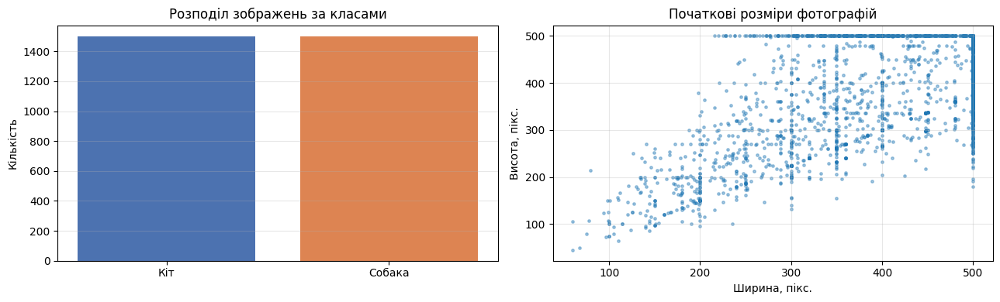

In [6]:
# Розподіл зображень за класами
class_counts = pd.Series(y_all).value_counts().sort_index()
print(pd.DataFrame({"Клас": class_names, "Кількість": class_counts.values}))

# Аналіз початкових розмірів фотографій (на відміну від CIFAR-10 вони різні)
sizes_df = pd.DataFrame(original_sizes, columns=["Висота", "Ширина"])
print("\nСтатистика початкових розмірів:")
print(sizes_df.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(class_names, class_counts.values, color=["#4C72B0", "#DD8452"])
axes[0].set_title("Розподіл зображень за класами")
axes[0].set_ylabel("Кількість")
axes[0].grid(axis="y", alpha=0.3)

axes[1].scatter(sizes_df["Ширина"], sizes_df["Висота"], s=6, alpha=0.4)
axes[1].set_title("Початкові розміри фотографій")
axes[1].set_xlabel("Ширина, пікс.")
axes[1].set_ylabel("Висота, пікс.")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

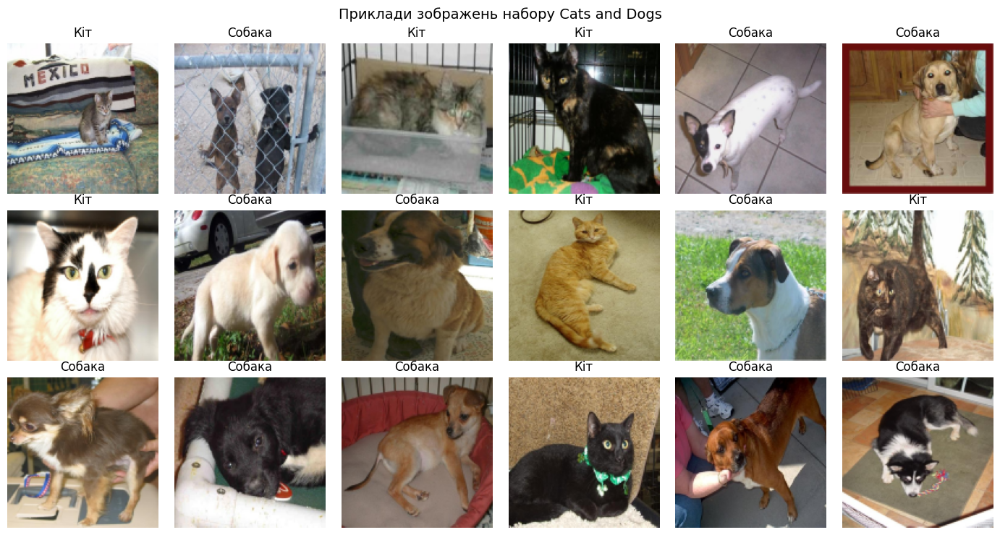

In [7]:
# Приклади зображень обох класів
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
rng_idx = np.random.default_rng(SEED).choice(len(X_all), size=18, replace=False)
for ax, idx in zip(axes.flat, rng_idx):
    ax.imshow(X_all[idx])
    ax.set_title(class_names[y_all[idx]])
    ax.axis("off")
plt.suptitle("Приклади зображень набору Cats and Dogs", fontsize=14)
plt.tight_layout()
plt.show()

Класи збалансовані (так сформовано вибірку), тому Accuracy є коректною основною метрикою. Водночас фотографії мають різні розміри, ракурси, фон та освітлення, а тварина часто займає лише частину кадру — це робить задачу складнішою, ніж CIFAR-10 з двома класами.

## 3. Попередня обробка зображень засобами OpenCV

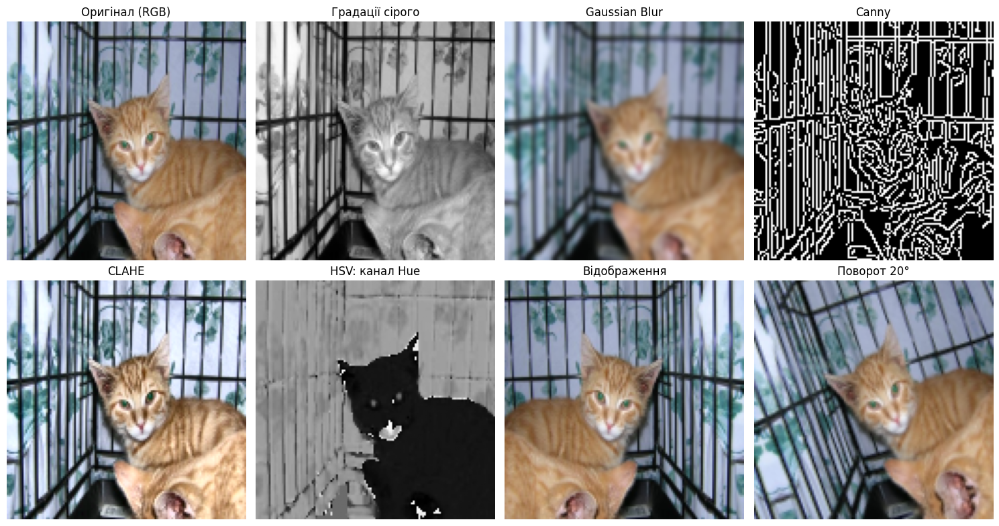

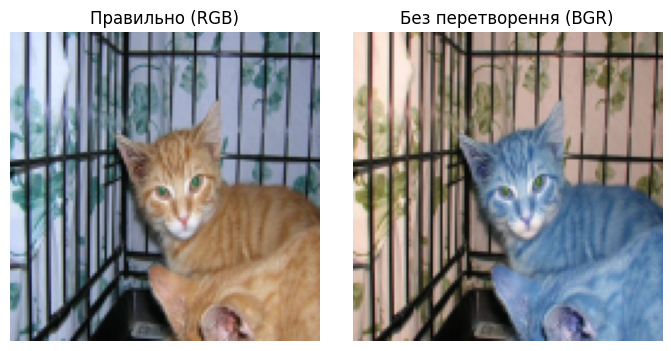

In [8]:
sample = X_all[5]
sample_bgr = cv2.cvtColor(sample, cv2.COLOR_RGB2BGR)          # формат OpenCV
gray = cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2GRAY)           # градації сірого
blur = cv2.GaussianBlur(sample, (5, 5), 0)                    # згладжування
edges = cv2.Canny(gray, 50, 150)                              # виділення контурів

# Вирівнювання контрасту CLAHE по каналу яскравості L у просторі LAB
lab = cv2.cvtColor(sample, cv2.COLOR_RGB2LAB)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
lab[:, :, 0] = clahe.apply(lab[:, :, 0])
clahe_img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

hsv = cv2.cvtColor(sample, cv2.COLOR_RGB2HSV)                 # простір HSV
flipped = cv2.flip(sample, 1)                                 # горизонтальне відображення

# Поворот на 20 градусів
h, w = sample.shape[:2]
M = cv2.getRotationMatrix2D((w / 2, h / 2), 20, 1.0)
rotated = cv2.warpAffine(sample, M, (w, h), borderMode=cv2.BORDER_REFLECT)

images = [sample, gray, blur, edges, clahe_img, hsv[:, :, 0], flipped, rotated]
titles = ["Оригінал (RGB)", "Градації сірого", "Gaussian Blur", "Canny",
          "CLAHE", "HSV: канал Hue", "Відображення", "Поворот 20°"]

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, img, title in zip(axes.flat, images, titles):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Демонстрація помилки порядку каналів: зображення BGR, показане як RGB
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(sample); axes[0].set_title("Правильно (RGB)")
axes[1].imshow(sample_bgr); axes[1].set_title("Без перетворення (BGR)")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

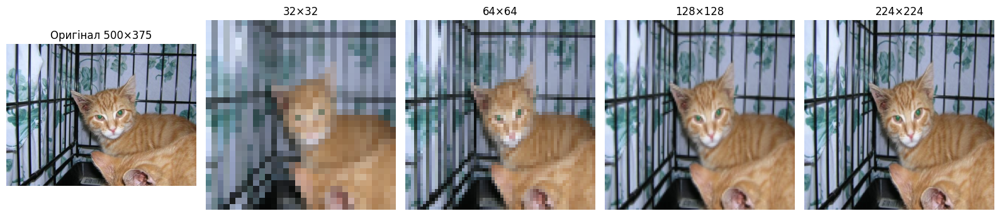

In [9]:
# Вплив роздільної здатності: як виглядає об'єкт при різних розмірах входу
original = cv2.cvtColor(cv2_imread(all_paths[5]), cv2.COLOR_BGR2RGB)
sizes = [32, 64, 128, 224]

fig, axes = plt.subplots(1, len(sizes) + 1, figsize=(16, 3.8))
axes[0].imshow(original)
axes[0].set_title(f"Оригінал {original.shape[1]}×{original.shape[0]}")
for ax, s in zip(axes[1:], sizes):
    ax.imshow(cv2.resize(original, (s, s), interpolation=cv2.INTER_AREA))
    ax.set_title(f"{s}×{s}")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

Розмір 32×32 (як у CIFAR-10) втрачає дрібні деталі морди та шерсті, а 224×224 значно збільшує обчислення. Розмір **128×128** — компроміс між збереженням ознак і швидкістю навчання. Для зменшення зображень використовуємо інтерполяцію `INTER_AREA`, яка дає найменше артефактів. Неквадратні фото при цьому дещо деформуються, але однаково для обох класів.

## 4. Підготовка навчальної, контрольної та тестової вибірок

In [10]:
# Розбиття 70 / 15 / 15 зі збереженням пропорцій класів (stratify)
X_train, X_temp, y_train, y_temp, paths_train, paths_temp = train_test_split(
    X_all, y_all, all_paths, test_size=0.30, random_state=SEED, stratify=y_all
)
X_val, X_test, y_val, y_test, paths_val, paths_test = train_test_split(
    X_temp, y_temp, paths_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Навчальна вибірка:", X_train.shape, "| частка собак:", y_train.mean().round(3))
print("Контрольна вибірка:", X_val.shape, "| частка собак:", y_val.mean().round(3))
print("Тестова вибірка:   ", X_test.shape, "| частка собак:", y_test.mean().round(3))

# Звільняємо пам'ять від загального масиву
del X_temp, y_temp

Навчальна вибірка: (2100, 128, 128, 3) | частка собак: 0.5
Контрольна вибірка: (450, 128, 128, 3) | частка собак: 0.5
Тестова вибірка:    (450, 128, 128, 3) | частка собак: 0.5


Зображення зберігаються як `uint8` (економія пам'яті), а **нормалізація ділення на 255** виконується в конвеєрі `tf.data` однаково для всіх вибірок. Аугментація також застосовується в конвеєрі й **лише до навчальної вибірки**, тому збережені моделі не містять випадкових шарів і їх простіше експортувати.

Оскільки класів два, вихідний шар має один нейрон із **sigmoid**, а функція втрат — **Binary Cross-Entropy** (окремий випадок категоріальної перехресної ентропії для двох класів).

### 4.1. Конвеєри аугментації (Keras та OpenCV)

In [11]:
# Геометрична аугментація засобами Keras
aug_keras_geom = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),          # до ±~29°
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name="aug_geom")

# Геометрична + фотометрична аугментація засобами Keras
aug_keras_full = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.25),
    layers.RandomBrightness(0.2, value_range=(0.0, 1.0)),
], name="aug_full")


def opencv_augment(image):
    # Аугментація засобами OpenCV (вхід і вихід — uint8 RGB)
    result = image.copy()
    h, w = result.shape[:2]

    # Горизонтальне відображення (кіт чи собака не змінюються від дзеркалення)
    if np.random.rand() > 0.5:
        result = cv2.flip(result, 1)

    # Поворот, масштабування та зсув однією афінною матрицею
    angle = np.random.uniform(-15, 15)
    scale = np.random.uniform(0.9, 1.15)
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    M[0, 2] += np.random.uniform(-0.1, 0.1) * w
    M[1, 2] += np.random.uniform(-0.1, 0.1) * h
    result = cv2.warpAffine(result, M, (w, h), borderMode=cv2.BORDER_REFLECT)

    # Зміна контрастності (alpha) та яскравості (beta)
    alpha = np.random.uniform(0.75, 1.25)
    beta = np.random.uniform(-30, 30)
    result = cv2.convertScaleAbs(result, alpha=alpha, beta=beta)

    # Зміна насиченості у просторі HSV
    hsv = cv2.cvtColor(result, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[:, :, 1] = np.clip(hsv[:, :, 1] * np.random.uniform(0.7, 1.3), 0, 255)
    result = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

    # Іноді — легке розмиття (імітація нечіткого фото)
    if np.random.rand() < 0.2:
        result = cv2.GaussianBlur(result, (3, 3), 0)
    return result


def tf_opencv_augment(image, label):
    # Обгортка, яка дозволяє викликати OpenCV всередині конвеєра tf.data
    augmented = tf.numpy_function(opencv_augment, [image], tf.uint8)
    augmented.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return augmented, label


def make_dataset(X, y, training=False, augment=None, batch_size=BATCH_SIZE):
    # Створює конвеєр tf.data: (аугментація OpenCV) -> нормалізація -> пакети -> (аугментація Keras)
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    if training and augment == "opencv":
        ds = ds.map(tf_opencv_augment, num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda img, lbl: (tf.cast(img, tf.float32) / 255.0, lbl),
                num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    if training and augment in ("keras_geom", "keras_full"):
        aug_layer = aug_keras_geom if augment == "keras_geom" else aug_keras_full
        ds = ds.map(lambda img, lbl: (tf.clip_by_value(aug_layer(img, training=True), 0.0, 1.0), lbl),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


# Незмінні конвеєри для оцінювання (без перемішування й аугментації)
train_eval_ds = make_dataset(X_train, y_train)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

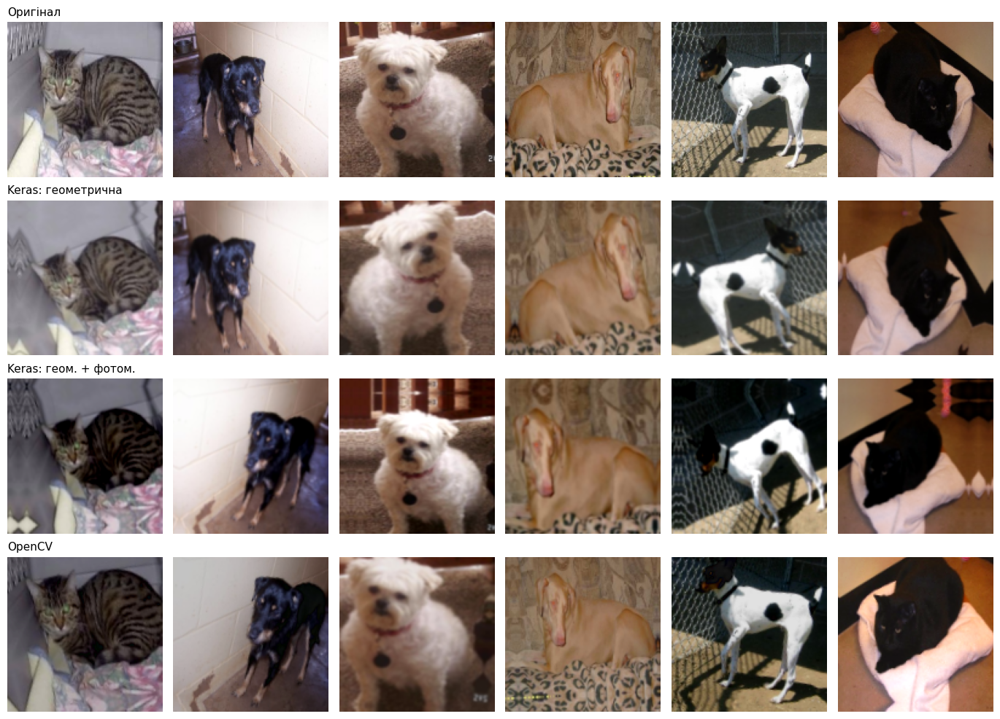

In [12]:
# Візуальна перевірка аугментації: оригінал, Keras (геом.), Keras (повна), OpenCV
n = 6
batch = tf.convert_to_tensor(X_train[:n].astype("float32") / 255.0)
geom = tf.clip_by_value(aug_keras_geom(batch, training=True), 0, 1).numpy()
full = tf.clip_by_value(aug_keras_full(batch, training=True), 0, 1).numpy()
ocv = np.array([opencv_augment(img) for img in X_train[:n]])

rows = [("Оригінал", X_train[:n]), ("Keras: геометрична", geom),
        ("Keras: геом. + фотом.", full), ("OpenCV", ocv)]
fig, axes = plt.subplots(4, n, figsize=(2.3 * n, 10))
for r, (title, imgs) in enumerate(rows):
    for c in range(n):
        axes[r, c].imshow(imgs[c])
        axes[r, c].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## 5. Архітектури CNN та допоміжні функції

Досліджуються дві архітектури:

* **Базова CNN** — 3 згорткові блоки (32-64-128 фільтрів, Conv → ReLU → MaxPooling), класифікаційна частина `Flatten → Dense(128) → Dropout → Dense(1, sigmoid)`. Через Flatten має багато параметрів у повнозв'язному шарі і схильна до перенавчання.
* **Глибока CNN** — 4 блоки по дві згортки (32-64-128-256 фільтрів) з Batch Normalization, класифікаційна частина `GlobalAveragePooling → Dense(128) → Dropout → Dense(1, sigmoid)`.

Регуляризація задається параметрами: `dropout_rate`, коефіцієнт L2 (`l2`) для всіх згорткових і повнозв'язних шарів, наявність Batch Normalization (`use_bn`) та тип аугментації.

In [13]:
def build_model(arch="base", dropout_rate=0.5, l2=0.0, use_bn=False):
    # Конструктор CNN для бінарної класифікації «кіт / собака»
    reg = regularizers.l2(l2) if l2 > 0 else None

    if arch == "base":
        block_filters, convs_per_block = (32, 64, 128), 1
    elif arch == "deep":
        block_filters, convs_per_block = (32, 64, 128, 256), 2
    else:
        raise ValueError("arch має бути 'base' або 'deep'")

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inputs
    for filters in block_filters:
        for _ in range(convs_per_block):
            # Якщо є BatchNormalization, зміщення (bias) у згортці зайве
            x = layers.Conv2D(filters, (3, 3), padding="same",
                              use_bias=not use_bn, kernel_regularizer=reg)(x)
            if use_bn:
                x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D((2, 2))(x)

    # Класифікаційна частина
    if arch == "base":
        x = layers.Flatten()(x)
    else:
        x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name=f"cnn_{arch}")


# Огляд структури обох архітектур
for arch in ["base", "deep"]:
    m = build_model(arch, use_bn=(arch == "deep"))
    m.summary()
    print()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Model: "cnn_deep"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             

 Total params: 1,208,161 (4.61 MB)

 Trainable params: 1,206,241 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [14]:
all_results = []      # підсумкові метрики всіх експериментів
histories = {}        # історії навчання
trained_models = {}   # навчені моделі
test_probas = {}      # ймовірності на тестовій вибірці


def predict_proba(model, X):
    # Ймовірність класу «Собака» для кожного зображення
    return model.predict(make_dataset(X, np.zeros(len(X))), verbose=0).ravel()


def run_experiment(name, group, arch="base", dropout_rate=0.5, l2=0.0,
                   use_bn=False, augment=None, epochs=EPOCHS, lr=1e-3):
    # Навчає одну модель і обчислює всі показники якості та узагальнення
    keras.utils.set_random_seed(SEED)            # однакова ініціалізація для чесного порівняння
    model = build_model(arch, dropout_rate, l2, use_bn)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=["accuracy"])

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    train_ds = make_dataset(X_train, y_train, training=True, augment=augment)

    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=callbacks, verbose=VERBOSE)
    train_time = time.perf_counter() - start

    # Точність на навчальній вибірці БЕЗ аугментації і Dropout — для оцінки розриву
    train_pred = (predict_proba(model, X_train) >= 0.5).astype(int)
    val_pred = (predict_proba(model, X_val) >= 0.5).astype(int)

    start = time.perf_counter()
    probs = predict_proba(model, X_test)
    inference_time = time.perf_counter() - start
    test_pred = (probs >= 0.5).astype(int)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    result = {
        "Модель": name,
        "Група": group,
        "Train Accuracy": train_acc,
        "Val Accuracy": accuracy_score(y_val, val_pred),
        "Test Accuracy": test_acc,
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1": f1_score(y_test, test_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probs),
        "Розрив train-test": train_acc - test_acc,
        "Мін. val_loss": min(history.history["val_loss"]),
        "Епох": len(history.history["loss"]),
        "Час навчання, с": train_time,
        "Час прогнозування 1 зобр., мс": 1000 * inference_time / len(X_test),
        "Параметри": model.count_params(),
    }
    all_results.append(result)
    histories[name] = history.history
    trained_models[name] = model
    test_probas[name] = probs

    print(f"{name:<45} train={train_acc:.3f}  val={result['Val Accuracy']:.3f}  "
          f"test={test_acc:.3f}  F1={result['F1']:.3f}  розрив={result['Розрив train-test']:+.3f}  "
          f"епох={result['Епох']}  {train_time:.0f} с")
    return model, history, result


def plot_histories(names, title):
    # Криві навчання: суцільна лінія — навчальна вибірка, пунктир — контрольна
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    colors = plt.cm.tab10.colors
    for i, name in enumerate(names):
        h = histories[name]
        c = colors[i % 10]
        axes[0].plot(h["loss"], color=c, label=f"{name} (train)")
        axes[0].plot(h["val_loss"], color=c, linestyle="--", label=f"{name} (val)")
        axes[1].plot(h["accuracy"], color=c)
        axes[1].plot(h["val_accuracy"], color=c, linestyle="--")
    axes[0].set_title("Функція втрат"); axes[0].set_xlabel("Епоха"); axes[0].set_ylabel("Loss")
    axes[1].set_title("Точність"); axes[1].set_xlabel("Епоха"); axes[1].set_ylabel("Accuracy")
    for ax in axes: ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8, ncol=1, loc="upper right")
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


def results_table(group=None):
    df = pd.DataFrame(all_results).drop_duplicates(subset=["Модель"], keep="last")
    if group is not None:
        df = df[df["Група"] == group]
    return df.set_index("Модель")

## 6. Експеримент 1. Вплив Dropout

Базова CNN, без аугментації та L2. Змінюємо лише частку вимкнених нейронів у повнозв'язній частині.

In [15]:
dropout_values = [0.0, 0.2, 0.3, 0.5, 0.7]
for rate in dropout_values:
    run_experiment(f"Dropout {rate}", "Dropout", arch="base", dropout_rate=rate)

dropout_df = results_table("Dropout")
dropout_df["Dropout"] = dropout_values
cols = ["Train Accuracy", "Val Accuracy", "Test Accuracy", "F1", "Розрив train-test", "Мін. val_loss", "Епох"]
print(dropout_df[cols].round(4))

Dropout 0.0                                   train=0.818  val=0.709  test=0.693  F1=0.691  розрив=+0.125  епох=13  46 с
Dropout 0.2                                   train=0.828  val=0.720  test=0.727  F1=0.712  розрив=+0.101  епох=13  27 с
Dropout 0.3                                   train=0.832  val=0.713  test=0.722  F1=0.723  розрив=+0.110  епох=14  28 с
Dropout 0.5                                   train=0.781  val=0.680  test=0.698  F1=0.644  розрив=+0.084  епох=14  25 с
Dropout 0.7                                   train=0.789  val=0.689  test=0.704  F1=0.665  розрив=+0.085  епох=15  27 с
             Train Accuracy  Val Accuracy  Test Accuracy      F1  \
Модель                                                             
Dropout 0.0          0.8181        0.7089         0.6933  0.6906   
Dropout 0.2          0.8281        0.7200         0.7267  0.7119   
Dropout 0.3          0.8324        0.7133         0.7222  0.7228   
Dropout 0.5          0.7814        0.6800         0.697

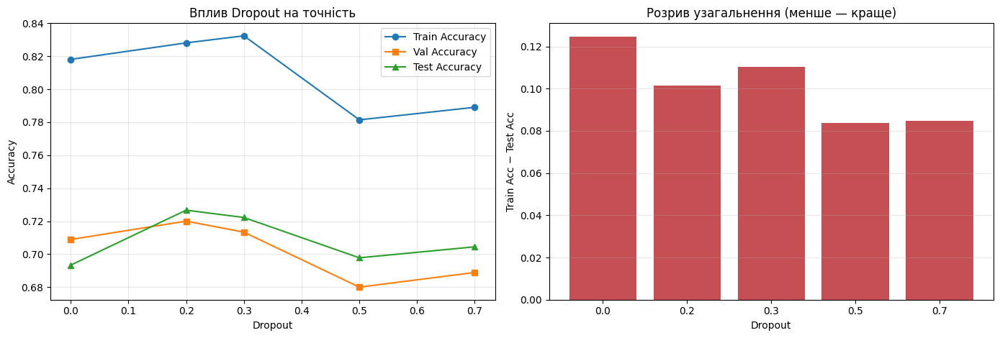

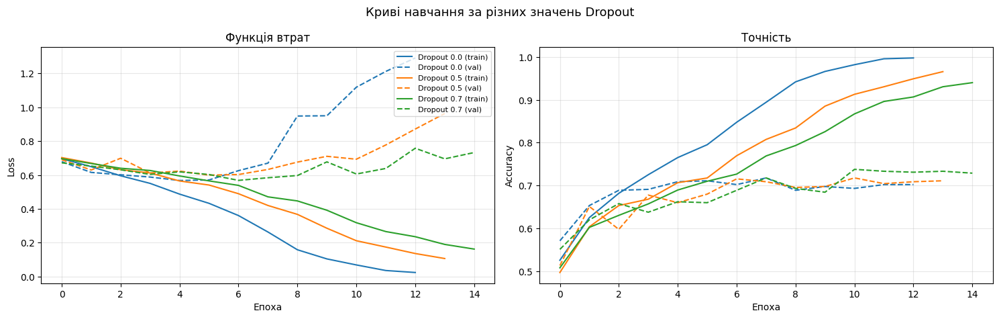

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(dropout_df["Dropout"], dropout_df["Train Accuracy"], marker="o", label="Train Accuracy")
axes[0].plot(dropout_df["Dropout"], dropout_df["Val Accuracy"], marker="s", label="Val Accuracy")
axes[0].plot(dropout_df["Dropout"], dropout_df["Test Accuracy"], marker="^", label="Test Accuracy")
axes[0].set_xlabel("Dropout"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Вплив Dropout на точність")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].bar(dropout_df["Dropout"].astype(str), dropout_df["Розрив train-test"], color="#C44E52")
axes[1].set_xlabel("Dropout"); axes[1].set_ylabel("Train Acc − Test Acc")
axes[1].set_title("Розрив узагальнення (менше — краще)")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plot_histories(["Dropout 0.0", "Dropout 0.5", "Dropout 0.7"], "Криві навчання за різних значень Dropout")

**Що аналізуємо:** без Dropout навчальна точність прямує до 1, а контрольна функція втрат після кількох епох починає зростати — класичне перенавчання. Збільшення Dropout зменшує розрив між навчальною та тестовою точністю. Надто велике значення (0.7) може уповільнювати навчання й знижувати точність через втрату корисної інформації. Найкраще значення визначається за **контрольною** вибіркою (код нижче).

In [17]:
best_dropout = float(dropout_df["Val Accuracy"].idxmax().split()[-1])
print("Найкраще значення Dropout за контрольною вибіркою:", best_dropout)

Найкраще значення Dropout за контрольною вибіркою: 0.2


## 7. Експеримент 2. Вплив аугментації (Keras та OpenCV)

Базова CNN з Dropout 0.5. Порівнюємо навчання без аугментації, з геометричною аугментацією Keras, з геометричною + фотометричною аугментацією Keras і з аугментацією OpenCV.

In [18]:
aug_configs = {
    "Без аугментації": None,
    "Аугм. Keras (геометрична)": "keras_geom",
    "Аугм. Keras (геом.+фотом.)": "keras_full",
    "Аугм. OpenCV": "opencv",
}
for name, aug in aug_configs.items():
    run_experiment(name, "Аугментація", arch="base", dropout_rate=0.5, augment=aug)

aug_df = results_table("Аугментація")
cols = ["Train Accuracy", "Val Accuracy", "Test Accuracy", "F1", "ROC AUC",
        "Розрив train-test", "Епох", "Час навчання, с"]
print(aug_df[cols].round(4))

Без аугментації                               train=0.808  val=0.711  test=0.727  F1=0.716  розрив=+0.081  епох=14  27 с
Аугм. Keras (геометрична)                     train=0.820  val=0.818  test=0.771  F1=0.775  розрив=+0.048  епох=40  379 с
Аугм. Keras (геом.+фотом.)                    train=0.808  val=0.762  test=0.747  F1=0.747  розрив=+0.061  епох=40  391 с
Аугм. OpenCV                                  train=0.829  val=0.782  test=0.791  F1=0.806  розрив=+0.037  епох=40  86 с
                            Train Accuracy  Val Accuracy  Test Accuracy  \
Модель                                                                    
Без аугментації                     0.8081        0.7111         0.7267   
Аугм. Keras (геометрична)           0.8195        0.8178         0.7711   
Аугм. Keras (геом.+фотом.)          0.8076        0.7622         0.7467   
Аугм. OpenCV                        0.8286        0.7822         0.7911   

                                F1  ROC AUC  Розрив train-test 

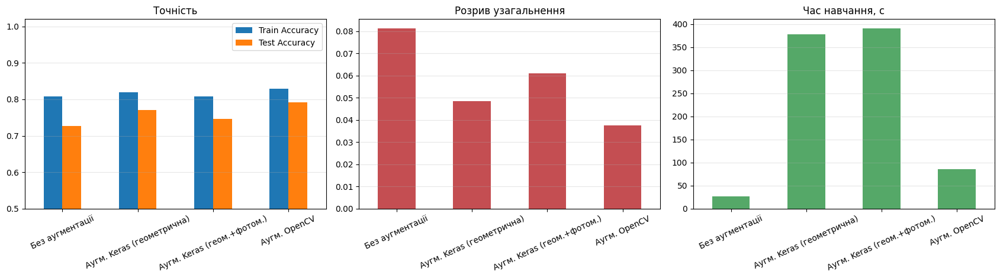

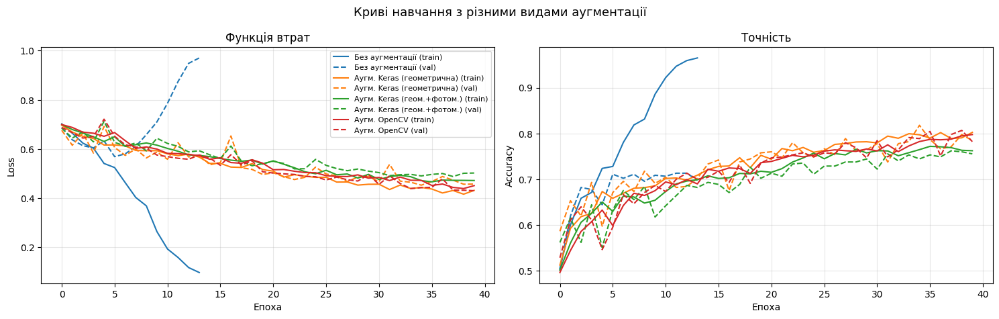

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
aug_df[["Train Accuracy", "Test Accuracy"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Точність"); axes[0].set_ylim(0.5, 1.02)
aug_df["Розрив train-test"].plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Розрив узагальнення")
aug_df["Час навчання, с"].plot(kind="bar", ax=axes[2], color="#55A868")
axes[2].set_title("Час навчання, с")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plot_histories(list(aug_configs.keys()), "Криві навчання з різними видами аугментації")

**Що аналізуємо:** аугментація фактично збільшує різноманітність навчальних прикладів, тому модель важче «запам'ятовує» конкретні фото. Як правило, навчальна точність знижується, контрольна функція втрат перестає зростати, а розрив узагальнення різко скорочується. Ціна — більша кількість епох до збіжності та довший час навчання (особливо для OpenCV, яка виконується на CPU через `tf.numpy_function`).

Горизонтальне відображення для котів і собак коректне, оскільки дзеркальне фото тварини належить до того самого класу (на відміну від тексту чи дорожніх знаків).

## 8. Експеримент 3. L2-регуляризація, Batch Normalization та їх поєднання

Щоб виділити ефект кожного механізму, спочатку вимикаємо Dropout і аугментацію, а потім поєднуємо всі методи.

In [20]:
reg_configs = [
    # (назва, параметри)
    ("Без регуляризації",                dict(dropout_rate=0.0, l2=0.0,  use_bn=False, augment=None)),
    ("L2 = 1e-4",                        dict(dropout_rate=0.0, l2=1e-4, use_bn=False, augment=None)),
    ("L2 = 1e-3",                        dict(dropout_rate=0.0, l2=1e-3, use_bn=False, augment=None)),
    ("Batch Normalization",              dict(dropout_rate=0.0, l2=0.0,  use_bn=True,  augment=None)),
    ("Dropout + L2 + аугм.",             dict(dropout_rate=0.5, l2=1e-4, use_bn=False, augment="keras_full")),
    ("Dropout + L2 + BN + аугм.",        dict(dropout_rate=0.5, l2=1e-4, use_bn=True,  augment="keras_full")),
]
for name, params in reg_configs:
    run_experiment(name, "Регуляризація", arch="base", **params)

reg_df = results_table("Регуляризація")
cols = ["Train Accuracy", "Val Accuracy", "Test Accuracy", "F1", "ROC AUC",
        "Розрив train-test", "Мін. val_loss", "Епох"]
print(reg_df[cols].round(4))

Без регуляризації                             train=0.858  val=0.722  test=0.693  F1=0.682  розрив=+0.164  епох=14  24 с
L2 = 1e-4                                     train=0.838  val=0.711  test=0.729  F1=0.723  розрив=+0.109  епох=16  30 с
L2 = 1e-3                                     train=0.790  val=0.696  test=0.671  F1=0.688  розрив=+0.118  епох=20  38 с
Batch Normalization                           train=0.850  val=0.687  test=0.707  F1=0.701  розрив=+0.143  епох=15  40 с
Dropout + L2 + аугм.                          train=0.784  val=0.744  test=0.731  F1=0.733  розрив=+0.053  епох=40  396 с
Dropout + L2 + BN + аугм.                     train=0.767  val=0.736  test=0.731  F1=0.734  розрив=+0.036  епох=40  401 с
                           Train Accuracy  Val Accuracy  Test Accuracy  \
Модель                                                                   
Без регуляризації                  0.8576        0.7222         0.6933   
L2 = 1e-4                          0.8376        0

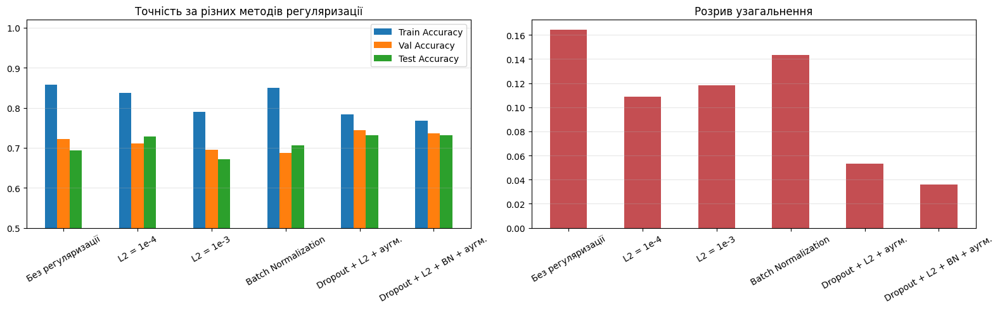

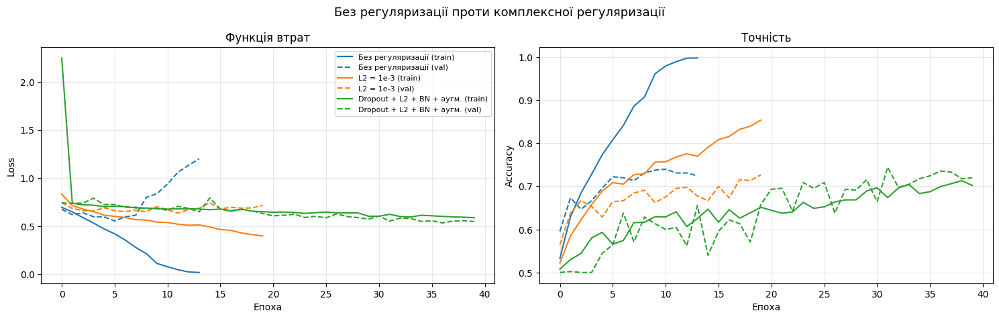

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
reg_df[["Train Accuracy", "Val Accuracy", "Test Accuracy"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Точність за різних методів регуляризації")
axes[0].set_ylim(0.5, 1.02)
reg_df["Розрив train-test"].plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Розрив узагальнення")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plot_histories(["Без регуляризації", "L2 = 1e-3", "Dropout + L2 + BN + аугм."],
               "Без регуляризації проти комплексної регуляризації")

**Що аналізуємо:**

* **L2** штрафує великі ваги (до функції втрат додається λ·Σw²), що робить модель «гладшою». Помірне λ зменшує перенавчання, а завелике — призводить до недонавчання.
* **Batch Normalization** передусім стабілізує та прискорює навчання; її регуляризувальний ефект слабкий, тому без інших методів перенавчання зазвичай залишається.
* **Поєднання** Dropout + L2 + аугментації, як правило, дає найменший розрив узагальнення й найкращу контрольну точність.

## 9. Експеримент 4. Порівняння архітектур

Глибока CNN (4 подвійні блоки, BN, Global Average Pooling) без регуляризації та з комплексною регуляризацією. Навчаємо довше, бо з аугментацією збіжність повільніша.

Глибока CNN (BN+GAP) без Dropout/L2/аугм.     train=0.941  val=0.818  test=0.811  F1=0.811  розрив=+0.130  епох=30  148 с
Глибока CNN (BN+GAP) + Dropout + L2 + аугм.   train=0.852  val=0.804  test=0.811  F1=0.805  розрив=+0.041  епох=37  409 с
                                             Train Accuracy  Val Accuracy  \
Модель                                                                      
Без регуляризації                                    0.8576        0.7222   
Dropout + L2 + BN + аугм.                            0.7671        0.7356   
Глибока CNN (BN+GAP) без Dropout/L2/аугм.            0.9410        0.8178   
Глибока CNN (BN+GAP) + Dropout + L2 + аугм.          0.8524        0.8044   

                                             Test Accuracy      F1  ROC AUC  \
Модель                                                                        
Без регуляризації                                   0.6933  0.6820   0.7851   
Dropout + L2 + BN + аугм.                           0.73

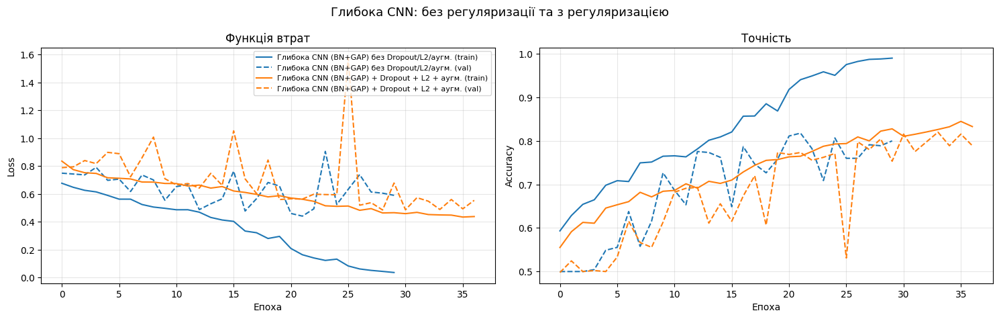

In [22]:
run_experiment("Глибока CNN (BN+GAP) без Dropout/L2/аугм.", "Архітектура",
               arch="deep", dropout_rate=0.0, l2=0.0, use_bn=True, augment=None)
run_experiment("Глибока CNN (BN+GAP) + Dropout + L2 + аугм.", "Архітектура",
               arch="deep", dropout_rate=0.5, l2=1e-4, use_bn=True, augment="keras_full",
               epochs=EPOCHS_LONG)

arch_names = ["Без регуляризації", "Dropout + L2 + BN + аугм.",
              "Глибока CNN (BN+GAP) без Dropout/L2/аугм.",
              "Глибока CNN (BN+GAP) + Dropout + L2 + аугм."]
arch_df = results_table().loc[arch_names]
cols = ["Train Accuracy", "Val Accuracy", "Test Accuracy", "F1", "ROC AUC",
        "Розрив train-test", "Параметри", "Час навчання, с"]
print(arch_df[cols].round(4))

plot_histories(arch_names[2:], "Глибока CNN: без регуляризації та з регуляризацією")

**Що аналізуємо:** завдяки Global Average Pooling глибока модель має значно менше параметрів у класифікаційній частині, ніж базова з Flatten, хоча містить більше згорткових шарів. Глибші ознаки та Batch Normalization зазвичай підвищують точність, але без регуляризації на невеликому наборі глибока модель також перенавчається.

## 10. Зведене порівняння всіх моделей

In [23]:
final_df = results_table().sort_values("Val Accuracy", ascending=False)
show_cols = ["Група", "Train Accuracy", "Val Accuracy", "Test Accuracy", "Precision",
             "Recall", "F1", "ROC AUC", "Розрив train-test", "Епох",
             "Час навчання, с", "Час прогнозування 1 зобр., мс", "Параметри"]
pd.set_option("display.width", 250)
print(final_df[show_cols].round(4).to_string())

os.makedirs("results", exist_ok=True)
final_df.to_csv("results/all_results.csv", encoding="utf-8-sig")

                                                     Група  Train Accuracy  Val Accuracy  Test Accuracy  Precision  Recall      F1  ROC AUC  Розрив train-test  Епох  Час навчання, с  Час прогнозування 1 зобр., мс  Параметри
Модель                                                                                                                                                                                                                         
Аугм. Keras (геометрична)                      Аугментація          0.8195        0.8178         0.7711     0.7629  0.7867  0.7746   0.8452             0.0484    40         378.5663                         0.3357    4287809
Глибока CNN (BN+GAP) без Dropout/L2/аугм.      Архітектура          0.9410        0.8178         0.8111     0.8125  0.8089  0.8107   0.8803             0.1298    30         148.0181                         0.5332    1208161
Глибока CNN (BN+GAP) + Dropout + L2 + аугм.    Архітектура          0.8524        0.8044         0.8111 

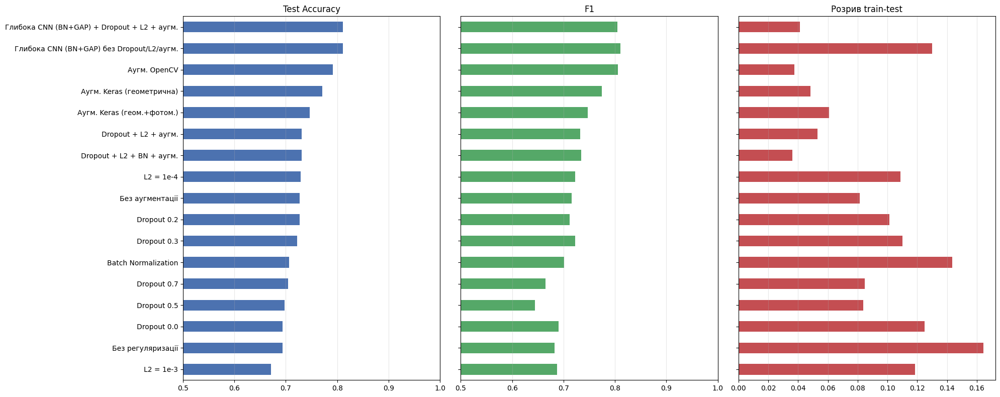

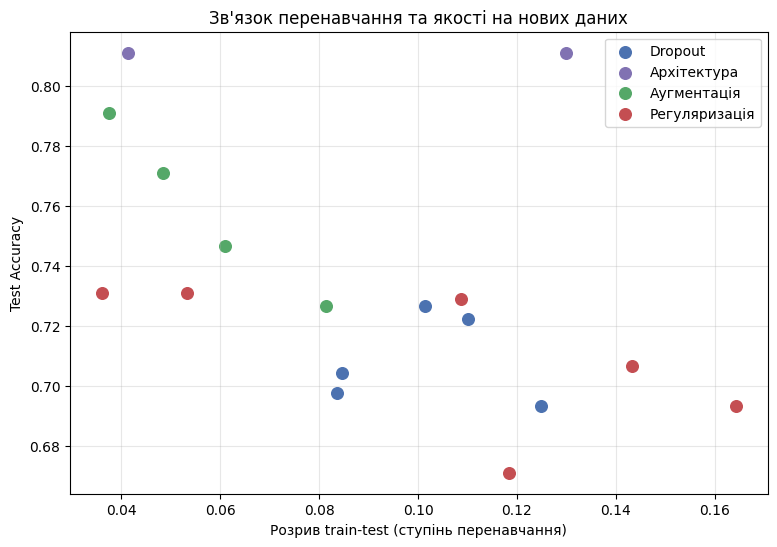

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
order = final_df.sort_values("Test Accuracy").index
final_df.loc[order, "Test Accuracy"].plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Test Accuracy"); axes[0].set_xlim(0.5, 1.0)
final_df.loc[order, "F1"].plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("F1"); axes[1].set_xlim(0.5, 1.0)
axes[1].set_yticklabels([])
final_df.loc[order, "Розрив train-test"].plot(kind="barh", ax=axes[2], color="#C44E52")
axes[2].set_title("Розрив train-test"); axes[2].set_yticklabels([])
for ax in axes:
    ax.grid(axis="x", alpha=0.3); ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Залежність тестової точності від розриву узагальнення
plt.figure(figsize=(9, 6))
colors = {"Dropout": "#4C72B0", "Аугментація": "#55A868", "Регуляризація": "#C44E52", "Архітектура": "#8172B2"}
for group, sub in final_df.groupby("Група"):
    plt.scatter(sub["Розрив train-test"], sub["Test Accuracy"], s=70, label=group, color=colors[group])
plt.xlabel("Розрив train-test (ступінь перенавчання)")
plt.ylabel("Test Accuracy")
plt.title("Зв'язок перенавчання та якості на нових даних")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [25]:
# Найкращу модель вибираємо за КОНТРОЛЬНОЮ вибіркою, тест використовуємо лише для звіту
best_name = final_df.index[0]
best_model = trained_models[best_name]
baseline_name = "Без регуляризації"     # модель для порівняння
baseline_model = trained_models[baseline_name]

print("Найкраща модель:", best_name)
print(final_df.loc[best_name, show_cols].to_string())

Найкраща модель: Аугм. Keras (геометрична)
Група                            Аугментація
Train Accuracy                      0.819524
Val Accuracy                        0.817778
Test Accuracy                       0.771111
Precision                           0.762931
Recall                              0.786667
F1                                  0.774617
ROC AUC                             0.845235
Розрив train-test                   0.048413
Епох                                      40
Час навчання, с                    378.56625
Час прогнозування 1 зобр., мс       0.335689
Параметри                            4287809


## 11. Аналіз якості та помилок найкращої моделі

              precision    recall  f1-score   support

         Кіт     0.7798    0.7556    0.7675       225
      Собака     0.7629    0.7867    0.7746       225

    accuracy                         0.7711       450
   macro avg     0.7714    0.7711    0.7711       450
weighted avg     0.7714    0.7711    0.7711       450



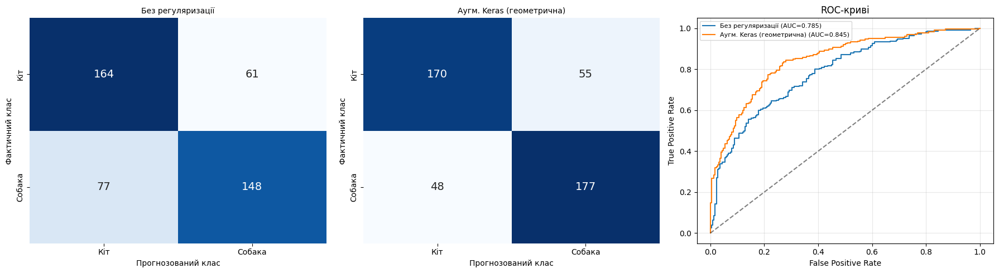

In [26]:
best_probs = test_probas[best_name]
best_pred = (best_probs >= 0.5).astype(int)

print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Матриці неточностей: модель без регуляризації та найкраща модель
for ax, name in zip(axes[:2], [baseline_name, best_name]):
    pred = (test_probas[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 14})
    ax.set_xlabel("Прогнозований клас"); ax.set_ylabel("Фактичний клас")
    ax.set_title(name, fontsize=10)

# ROC-криві
for name in [baseline_name, best_name]:
    fpr, tpr, _ = roc_curve(y_test, test_probas[name])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, test_probas[name]):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[2].set_xlabel("False Positive Rate"); axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("ROC-криві"); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

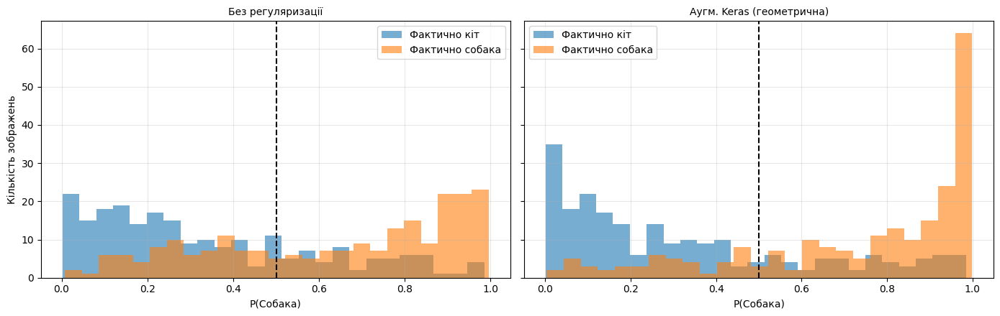

Без регуляризації: помилок 138, з них упевнених (>0.9): 9
Аугм. Keras (геометрична): помилок 103, з них упевнених (>0.9): 22


In [27]:
# Розподіл прогнозованих ймовірностей: впевненість моделей
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, [baseline_name, best_name]):
    p = test_probas[name]
    ax.hist(p[y_test == 0], bins=25, alpha=0.6, label="Фактично кіт")
    ax.hist(p[y_test == 1], bins=25, alpha=0.6, label="Фактично собака")
    ax.axvline(0.5, color="k", linestyle="--")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("P(Собака)")
    ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("Кількість зображень")
plt.tight_layout()
plt.show()

# Частка помилок, зроблених із високою впевненістю (> 0.9)
for name in [baseline_name, best_name]:
    p = test_probas[name]
    pred = (p >= 0.5).astype(int)
    conf = np.where(pred == 1, p, 1 - p)
    wrong = pred != y_test
    print(f"{name}: помилок {wrong.sum()}, з них упевнених (>0.9): {(wrong & (conf > 0.9)).sum()}")

Модель без регуляризації зазвичай надмірно впевнена: ймовірності зосереджені біля 0 і 1 навіть для помилкових прогнозів. Регуляризована модель дає обережніші оцінки, а впевнених помилок у неї менше.

Кількість помилок: 103 з 450
Кіт → Собака: 55
Собака → Кіт: 48


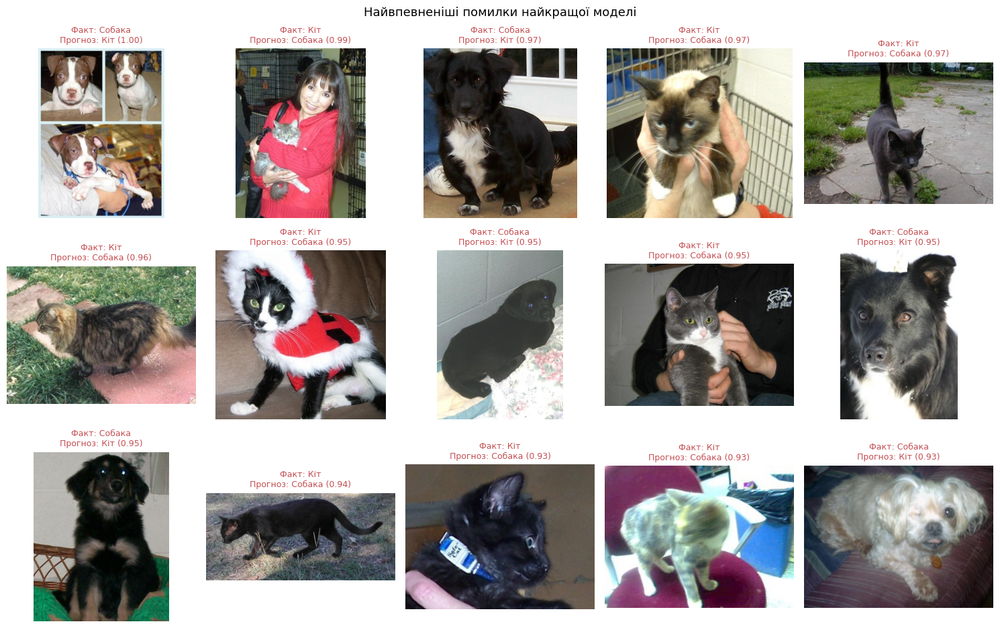

In [28]:
# Неправильно класифіковані зображення найкращої моделі (найвпевненіші помилки першими)
wrong_idx = np.where(best_pred != y_test)[0]
confidence = np.where(best_pred == 1, best_probs, 1 - best_probs)
wrong_idx = wrong_idx[np.argsort(-confidence[wrong_idx])]

print("Кількість помилок:", len(wrong_idx), "з", len(y_test))
print("Кіт → Собака:", int(((y_test == 0) & (best_pred == 1)).sum()))
print("Собака → Кіт:", int(((y_test == 1) & (best_pred == 0)).sum()))

fig, axes = plt.subplots(3, 5, figsize=(15, 9.5))
for ax, i in zip(axes.flat, wrong_idx[:15]):
    # Показуємо оригінальне фото у повній роздільній здатності
    img = cv2.cvtColor(cv2_imread(paths_test[i]), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"Факт: {class_names[y_test[i]]}\nПрогноз: {class_names[best_pred[i]]} ({confidence[i]:.2f})",
                 fontsize=9, color="#C44E52")
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Найвпевненіші помилки найкращої моделі", fontsize=13)
plt.tight_layout()
plt.show()

**Аналіз помилок:** типові причини — тварина займає малу частину кадру, у кадрі є люди або кілька тварин, нетипова поза чи ракурс, сильне затемнення/пересвічення, а також собаки малих порід із «котячою» мордою. Після масштабування до 128×128 частина дрібних деталей зникає.

## 12. Перевірка стійкості моделей до спотворень (OpenCV)

Здатність до узагальнення перевіримо ще одним способом: застосуємо до тестових зображень перетворення OpenCV, яких модель не бачила у «чистому» вигляді, і порівняємо модель без регуляризації та найкращу модель.

                         Без регуляризації  Аугм. Keras (геометрична)
Спотворення                                                          
Оригінал                            0.6933                     0.7711
Відображення                        0.7000                     0.7711
Поворот 20°                         0.6733                     0.7622
Розмиття 5×5                        0.6733                     0.7600
Яскравість +50                      0.6667                     0.6956
Контраст ×0.5                       0.5844                     0.6267
Гаусів шум                          0.6844                     0.7378
Обрізання 80% + масштаб             0.6667                     0.7444


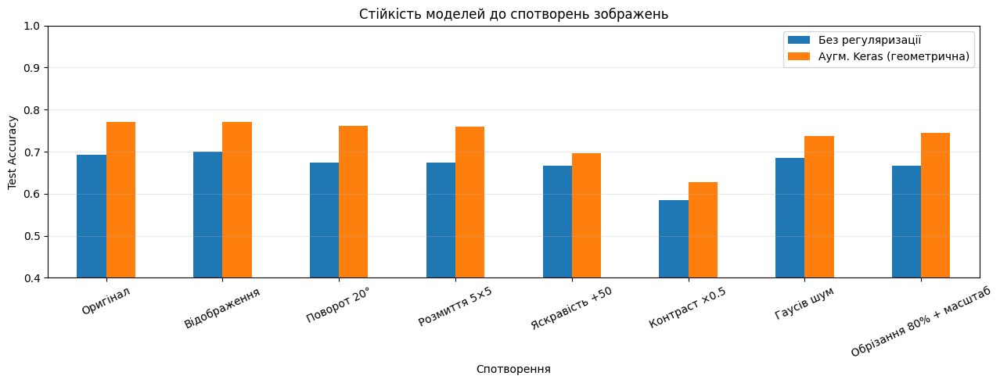

In [29]:
def perturb(images, kind):
    out = []
    for img in images:
        if kind == "Оригінал":
            r = img
        elif kind == "Відображення":
            r = cv2.flip(img, 1)
        elif kind == "Поворот 20°":
            M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), 20, 1.0)
            r = cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT)
        elif kind == "Розмиття 5×5":
            r = cv2.GaussianBlur(img, (5, 5), 0)
        elif kind == "Яскравість +50":
            r = cv2.convertScaleAbs(img, alpha=1.0, beta=50)
        elif kind == "Контраст ×0.5":
            r = cv2.convertScaleAbs(img, alpha=0.5, beta=64)
        elif kind == "Гаусів шум":
            noise = np.random.default_rng(SEED).normal(0, 15, img.shape)
            r = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
        elif kind == "Обрізання 80% + масштаб":
            m = int(IMG_SIZE * 0.1)
            r = cv2.resize(img[m:-m, m:-m], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        out.append(r)
    return np.array(out, dtype=np.uint8)


perturbations = ["Оригінал", "Відображення", "Поворот 20°", "Розмиття 5×5",
                 "Яскравість +50", "Контраст ×0.5", "Гаусів шум", "Обрізання 80% + масштаб"]
robust_rows = []
for kind in perturbations:
    Xp = perturb(X_test, kind)
    row = {"Спотворення": kind}
    for name in [baseline_name, best_name]:
        row[name] = accuracy_score(y_test, (predict_proba(trained_models[name], Xp) >= 0.5).astype(int))
    robust_rows.append(row)

robust_df = pd.DataFrame(robust_rows).set_index("Спотворення")
print(robust_df.round(4))

robust_df.plot(kind="bar", figsize=(13, 5))
plt.ylabel("Test Accuracy"); plt.ylim(0.4, 1.0)
plt.title("Стійкість моделей до спотворень зображень")
plt.xticks(rotation=25); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Візуалізація карт ознак і згорткових фільтрів

0 conv2d_29 (None, 128, 128, 32)
1 conv2d_30 (None, 64, 64, 64)
2 conv2d_31 (None, 32, 32, 128)


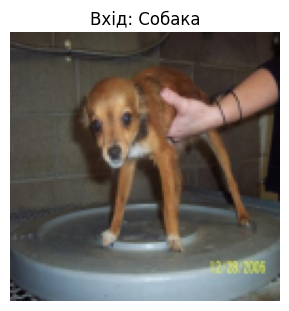

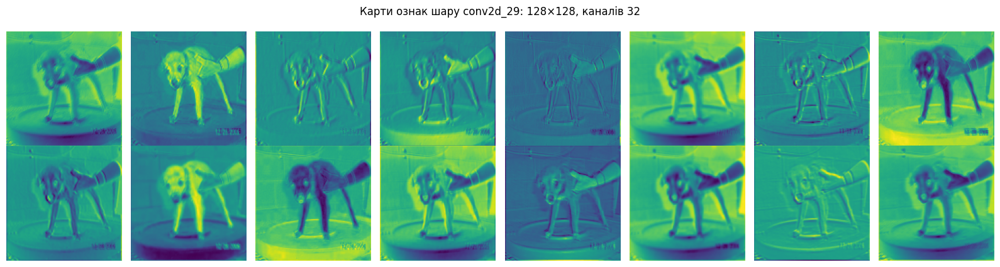

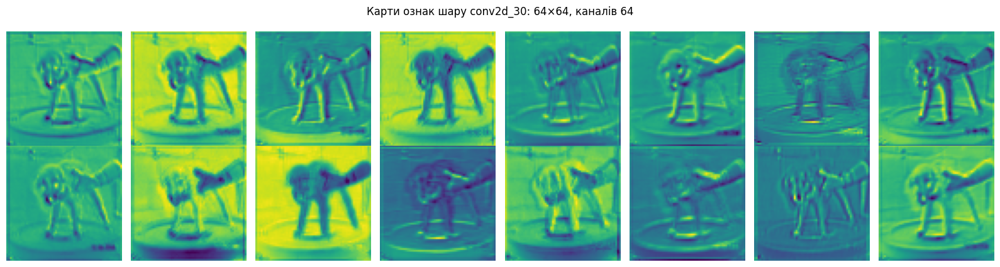

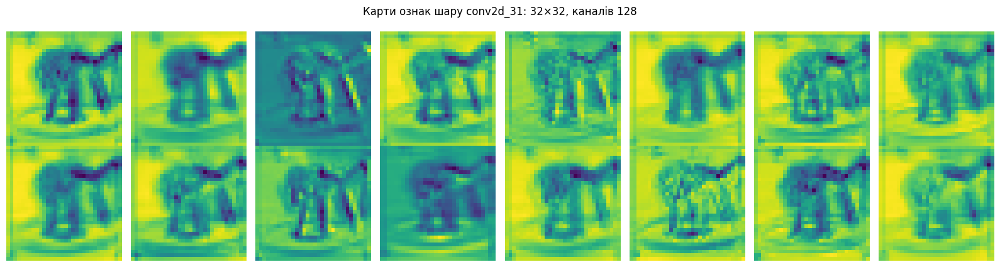

In [30]:
conv_layers = [l for l in best_model.layers if isinstance(l, layers.Conv2D)]
for i, l in enumerate(conv_layers):
    print(i, l.name, l.output.shape)

feature_model = keras.Model(inputs=best_model.inputs, outputs=[l.output for l in conv_layers])

img_idx = 0
feature_maps = feature_model.predict(X_test[img_idx:img_idx + 1].astype("float32") / 255.0, verbose=0)

plt.figure(figsize=(3.5, 3.5))
plt.imshow(X_test[img_idx])
plt.title(f"Вхід: {class_names[y_test[img_idx]]}")
plt.axis("off")
plt.show()

# Перший, середній і останній згорткові шари
for layer_i in sorted({0, len(conv_layers) // 2, len(conv_layers) - 1}):
    maps = feature_maps[layer_i][0]
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.3))
    for k, ax in enumerate(axes.flat):
        if k < maps.shape[-1]:
            ax.imshow(maps[:, :, k], cmap="viridis")
        ax.axis("off")
    plt.suptitle(f"Карти ознак шару {conv_layers[layer_i].name}: "
                 f"{maps.shape[0]}×{maps.shape[1]}, каналів {maps.shape[-1]}")
    plt.tight_layout()
    plt.show()

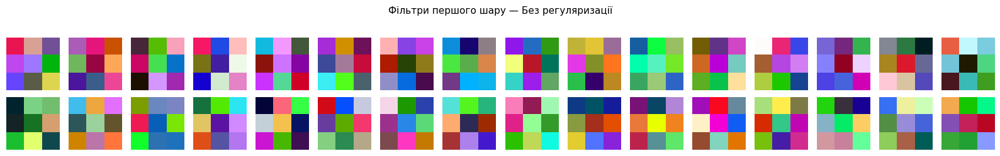

Без регуляризації: середня абсолютна вага першого шару = 0.0708


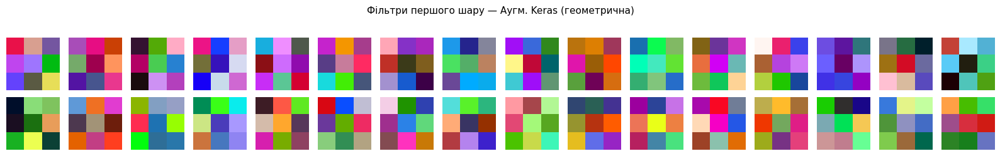

Аугм. Keras (геометрична): середня абсолютна вага першого шару = 0.0757


In [31]:
# Навчені фільтри першого згорткового шару (3×3×3) обох моделей
for name in [baseline_name, best_name]:
    first_conv = [l for l in trained_models[name].layers if isinstance(l, layers.Conv2D)][0]
    kernels = first_conv.get_weights()[0]          # форма (3, 3, 3, кількість фільтрів)
    fig, axes = plt.subplots(2, 16, figsize=(16, 2.6))
    for k, ax in enumerate(axes.flat):
        if k < kernels.shape[-1]:
            kern = kernels[:, :, :, k]
            kern = (kern - kern.min()) / (kern.max() - kern.min() + 1e-8)   # нормалізація для показу
            ax.imshow(kern)
        ax.axis("off")
    plt.suptitle(f"Фільтри першого шару — {name}", fontsize=11)
    plt.tight_layout()
    plt.show()
    print(f"{name}: середня абсолютна вага першого шару = {np.abs(kernels).mean():.4f}")

На перших шарах карти ознак мають розмір 128×128 і нагадують результати виділення меж, кольорових плям і текстур. На глибших шарах просторова розмірність зменшується (після кожного MaxPooling удвічі), а кількість каналів зростає — активації стають абстрактнішими й реагують на частини об'єкта (вуха, очі, ніс, контур голови). Фільтри першого шару — це навчені ваги, а не задані вручну детектори; L2 зменшує їхні абсолютні значення.

## 14. Розпізнавання власних зображень засобами OpenCV

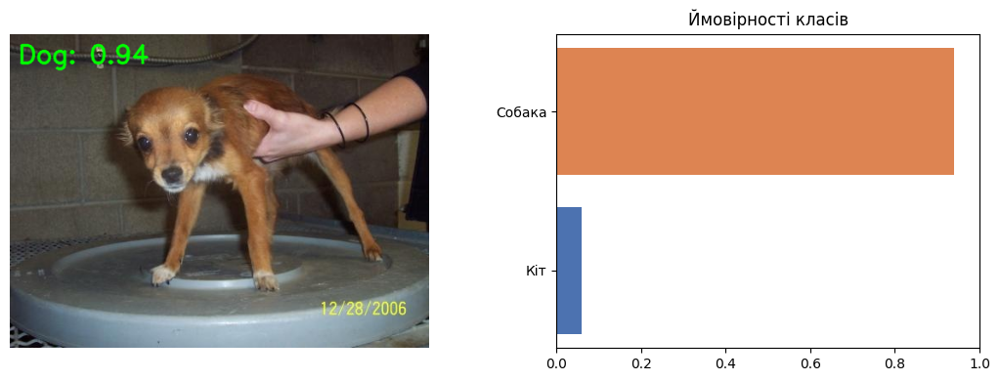

{'class': 'Собака', 'confidence': np.float64(0.9404528141021729), 'probabilities': array([0.05954719, 0.94045281])}


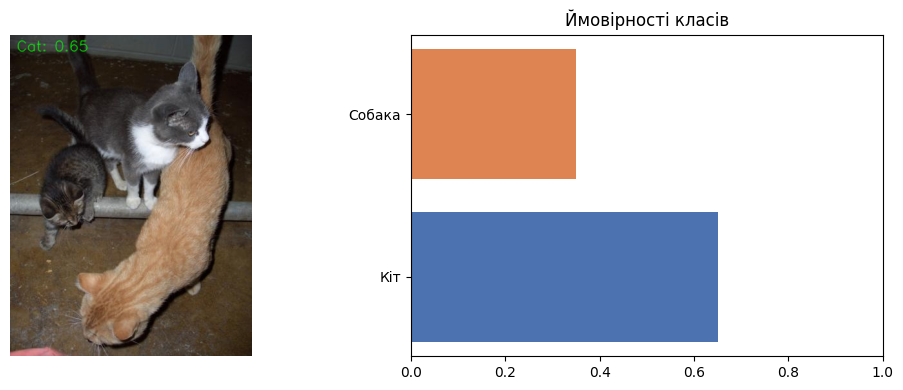

{'class': 'Кіт', 'confidence': np.float64(0.6495963633060455), 'probabilities': array([0.64959636, 0.35040364])}


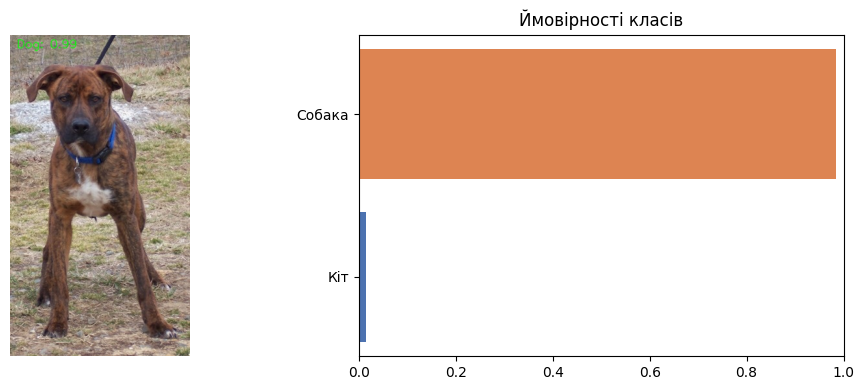

{'class': 'Собака', 'confidence': np.float64(0.9854515194892883), 'probabilities': array([0.01454848, 0.98545152])}


In [32]:
def predict_image(image_path, model, show=True):
    # Повний конвеєр: OpenCV (читання, BGR->RGB, масштабування) -> нормалізація -> CNN
    image = cv2_imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Не вдалося відкрити файл: {image_path}")
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    batch = np.expand_dims(resized.astype("float32") / 255.0, axis=0)

    p_dog = float(model.predict(batch, verbose=0)[0, 0])
    probs = np.array([1 - p_dog, p_dog])
    pred = int(p_dog >= 0.5)

    if show:
        # Підпис на зображенні засобами OpenCV
        annotated = image.copy()
        text = f"{['Cat', 'Dog'][pred]}: {probs[pred]:.2f}"
        scale = max(annotated.shape[1] / 500, 0.6)
        cv2.putText(annotated, text, (10, int(35 * scale)), cv2.FONT_HERSHEY_SIMPLEX,
                    scale, (0, 255, 0), max(int(2 * scale), 1), cv2.LINE_AA)
        fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})
        axes[0].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        axes[0].axis("off")
        axes[1].barh(class_names, probs, color=["#4C72B0", "#DD8452"])
        axes[1].set_xlim(0, 1); axes[1].set_title("Ймовірності класів")
        plt.tight_layout()
        plt.show()
    return {"class": class_names[pred], "confidence": probs[pred], "probabilities": probs}


# Демонстрація на кількох тестових файлах (повна роздільна здатність, як «нові» фото)
for path in paths_test[:3]:
    print(predict_image(path, best_model))

Saving изображение_2026-11-22_195728779.png to изображение_2026-11-22_195728779.png


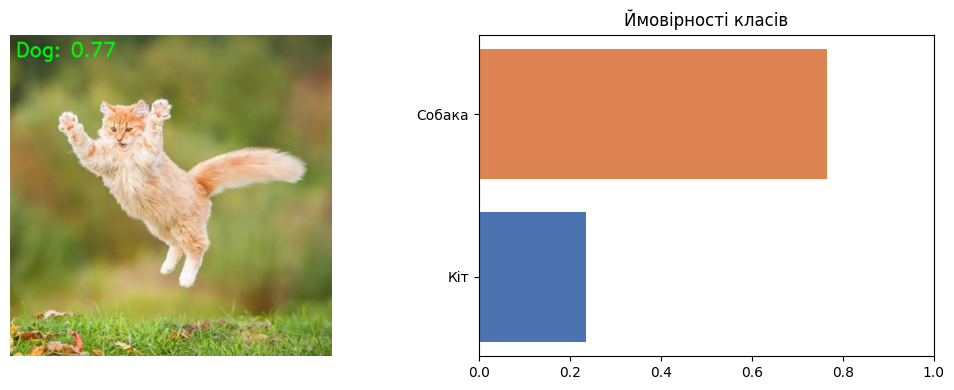

изображение_2026-11-22_195728779.png {'class': 'Собака', 'confidence': np.float64(0.7650601863861084), 'probabilities': array([0.23493981, 0.76506019])}


In [33]:
# Завантаження власних фотографій у Google Colab
try:
    from google.colab import files
    uploaded = files.upload()
    for fname in uploaded.keys():
        print(fname, predict_image(fname, best_model))
except ImportError:
    # Локальне середовище: вкажіть шлях до свого файлу
    my_path = "my_image.jpg"
    if os.path.exists(my_path):
        print(predict_image(my_path, best_model))
    else:
        print("Покладіть фото у файл my_image.jpg або змініть шлях")

Модель завжди вибирає один із двох класів, тому фото без кота чи собаки однаково буде віднесено до одного з них — це обмеження бінарного класифікатора. Висока ймовірність відображає впевненість у межах навченого розподілу даних, а не гарантію правильності.

## 15. Дослідження швидкодії

In [34]:
def benchmark_model(model, images, batch_size=1, repetitions=30):
    batch = images[:batch_size].astype("float32") / 255.0
    model(batch, training=False)                       # прогрів
    start = time.perf_counter()
    for _ in range(repetitions):
        model(batch, training=False)
    per_batch = (time.perf_counter() - start) / repetitions
    return per_batch * 1000, batch_size / per_batch     # мс на пакет, зображень/с


bench_rows = []
for name in [baseline_name, "Dropout + L2 + BN + аугм.",
             "Глибока CNN (BN+GAP) без Dropout/L2/аугм.", "Глибока CNN (BN+GAP) + Dropout + L2 + аугм."]:
    model = trained_models[name]
    ms1, fps1 = benchmark_model(model, X_test, batch_size=1)
    ms32, fps32 = benchmark_model(model, X_test, batch_size=32)
    bench_rows.append({"Модель": name, "Параметри": model.count_params(),
                       "мс / 1 зображення": ms1, "зобр./с (batch=1)": fps1,
                       "зобр./с (batch=32)": fps32,
                       "Час навчання, с": final_df.loc[name, "Час навчання, с"]})

bench_df = pd.DataFrame(bench_rows).set_index("Модель")
print(bench_df.round(2))

                                             Параметри  мс / 1 зображення  зобр./с (batch=1)  зобр./с (batch=32)  Час навчання, с
Модель                                                                                                                           
Без регуляризації                              4287809              10.96              91.28             2442.30            23.89
Dropout + L2 + BN + аугм.                      4288481              12.64              79.11             2065.65           400.60
Глибока CNN (BN+GAP) без Dropout/L2/аугм.      1208161              27.14              36.84             1071.94           148.02
Глибока CNN (BN+GAP) + Dropout + L2 + аугм.    1208161              26.26              38.08             1106.61           409.35


Регуляризація (Dropout, L2, аугментація) не змінює швидкодію прогнозування — Dropout і аугментація діють лише під час навчання, а L2 — це лише доданок до функції втрат. Швидкість визначається архітектурою: кількістю згорткових шарів і розміром карт ознак. Пакетна обробка значно збільшує пропускну здатність.

## 16. Збереження та експорт найкращої моделі

In [35]:
os.makedirs("saved_models", exist_ok=True)
model_path = "saved_models/cats_dogs_best.keras"
best_model.save(model_path)
print("Модель збережено:", model_path)

metadata = {
    "variant": 4,
    "task": "Розпізнавання котів і собак",
    "dataset": f"Microsoft Cats vs Dogs (Hugging Face), вибірка {2 * N_PER_CLASS} зображень",
    "split": {"train": int(len(X_train)), "val": int(len(X_val)), "test": int(len(X_test))},
    "classes": class_names,
    "input_shape": [IMG_SIZE, IMG_SIZE, 3],
    "color_order": "RGB (після cv2.cvtColor(BGR2RGB))",
    "resize_interpolation": "cv2.INTER_AREA",
    "normalization": "divide_by_255",
    "output": "sigmoid, P(Собака); поріг 0.5",
    "best_model": best_name,
    "metrics_test": {k: float(final_df.loc[best_name, k])
                     for k in ["Test Accuracy", "Precision", "Recall", "F1", "ROC AUC"]},
    "framework": "TensorFlow/Keras",
    "tensorflow_version": tf.__version__,
    "opencv_version": cv2.__version__,
}
with open("saved_models/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print(json.dumps(metadata, ensure_ascii=False, indent=2))

Модель збережено: saved_models/cats_dogs_best.keras
{
  "variant": 4,
  "task": "Розпізнавання котів і собак",
  "dataset": "Microsoft Cats vs Dogs (Hugging Face), вибірка 3000 зображень",
  "split": {
    "train": 2100,
    "val": 450,
    "test": 450
  },
  "classes": [
    "Кіт",
    "Собака"
  ],
  "input_shape": [
    128,
    128,
    3
  ],
  "color_order": "RGB (після cv2.cvtColor(BGR2RGB))",
  "resize_interpolation": "cv2.INTER_AREA",
  "normalization": "divide_by_255",
  "output": "sigmoid, P(Собака); поріг 0.5",
  "best_model": "Аугм. Keras (геометрична)",
  "metrics_test": {
    "Test Accuracy": 0.7711111111111111,
    "Precision": 0.7629310344827587,
    "Recall": 0.7866666666666666,
    "F1": 0.774617067833698,
    "ROC AUC": 0.8452345679012347
  },
  "framework": "TensorFlow/Keras",
  "tensorflow_version": "2.21.0",
  "opencv_version": "4.14.0"
}


In [36]:
# Повторне завантаження та перевірка збігу прогнозів
loaded_model = keras.models.load_model(model_path)
p_orig = best_model.predict(X_test[:20].astype("float32") / 255.0, verbose=0)
p_load = loaded_model.predict(X_test[:20].astype("float32") / 255.0, verbose=0)
print("Максимальна різниця прогнозів:", float(np.max(np.abs(p_orig - p_load))))
print("Прогнози збереженої моделі:", (p_load.ravel() >= 0.5).astype(int))
print("Фактичні мітки:            ", y_test[:20])

Максимальна різниця прогнозів: 0.0
Прогнози збереженої моделі: [1 0 1 0 0 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1]
Фактичні мітки:             [1 0 1 0 0 1 1 0 0 1 1 1 0 1 0 1 1 0 1 1]


In [37]:
# Експорт у TensorFlow Lite
tflite_path = "saved_models/cats_dogs_best.tflite"
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
    tflite_model = converter.convert()
except Exception as e:
    # Запасний шлях для нових версій Keras 3: через SavedModel
    print("Пряма конвертація не вдалася, використовуємо SavedModel:", type(e).__name__)
    best_model.export("saved_models/saved_model")
    converter = tf.lite.TFLiteConverter.from_saved_model("saved_models/saved_model")
    tflite_model = converter.convert()

with open(tflite_path, "wb") as f:
    f.write(tflite_model)
print(f"TFLite-модель: {os.path.getsize(tflite_path) / 1e6:.2f} МБ, "
      f".keras: {os.path.getsize(model_path) / 1e6:.2f} МБ")

# Перевірка прогнозування інтерпретатором TFLite
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

tflite_probs = []
for img in X_test[:50]:
    interpreter.set_tensor(inp["index"], (img[None].astype(np.float32) / 255.0))
    interpreter.invoke()
    tflite_probs.append(interpreter.get_tensor(out["index"])[0, 0])
tflite_probs = np.array(tflite_probs)
keras_probs = test_probas[best_name][:50]
print("Максимальна різниця Keras / TFLite:", float(np.max(np.abs(tflite_probs - keras_probs))))
print("Збіг класів:", np.mean((tflite_probs >= 0.5) == (keras_probs >= 0.5)))

Saved artifact at '/tmp/tmpvv414d00'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_143')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  134406687006288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634783376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634792208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634783184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634783568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634793744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634793552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634798352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634787600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134406634787984: TensorSpec(shape=(), dtype=tf.resource, name=None)
TFLite-модел

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Максимальна різниця Keras / TFLite: 3.8743019104003906e-07
Збіг класів: 1.0


In [38]:
# Архівуємо результати для завантаження
shutil.make_archive("lab7_variant4_results", "zip", ".", "saved_models")
try:
    from google.colab import files
    files.download("lab7_variant4_results.zip")
    files.download("results/all_results.csv")
except ImportError:
    print("Архів збережено: lab7_variant4_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Висновки

Нижче висновки формуються автоматично на основі отриманих чисел, щоб вони точно відповідали запуску.

In [39]:
r = results_table()

def g(name, col):
    return r.loc[name, col]

no_reg, full_reg = "Без регуляризації", "Dropout + L2 + BN + аугм."
deep_noreg = "Глибока CNN (BN+GAP) без Dropout/L2/аугм."
deep_reg = "Глибока CNN (BN+GAP) + Dropout + L2 + аугм."
best_aug = r[r["Група"] == "Аугментація"]["Val Accuracy"].idxmax()

lines = [
    f"1. Без регуляризації базова CNN досягла train accuracy {g(no_reg, 'Train Accuracy'):.3f} при test accuracy "
    f"{g(no_reg, 'Test Accuracy'):.3f}; розрив {g(no_reg, 'Розрив train-test'):.3f} свідчить про перенавчання.",
    f"2. Dropout: найкраще значення за контрольною вибіркою — {best_dropout}; "
    f"розрив змінився від {g('Dropout 0.0', 'Розрив train-test'):.3f} (Dropout 0) до "
    f"{g(f'Dropout {best_dropout}', 'Розрив train-test'):.3f}, test accuracy — "
    f"{g(f'Dropout {best_dropout}', 'Test Accuracy'):.3f}.",
    f"3. Аугментація: найкращий варіант — «{best_aug}» (test accuracy {g(best_aug, 'Test Accuracy'):.3f}, "
    f"розрив {g(best_aug, 'Розрив train-test'):.3f} проти {g('Без аугментації', 'Розрив train-test'):.3f} без аугментації); "
    f"час навчання зріс з {g('Без аугментації', 'Час навчання, с'):.0f} до {g(best_aug, 'Час навчання, с'):.0f} с.",
    f"4. L2: при λ=1e-4 test accuracy {g('L2 = 1e-4', 'Test Accuracy'):.3f}, при λ=1e-3 — {g('L2 = 1e-3', 'Test Accuracy'):.3f}; "
    f"Batch Normalization без інших методів — {g('Batch Normalization', 'Test Accuracy'):.3f} "
    f"(розрив {g('Batch Normalization', 'Розрив train-test'):.3f}).",
    f"5. Комплексна регуляризація (Dropout + L2 + BN + аугментація) у базовій CNN: test accuracy "
    f"{g(full_reg, 'Test Accuracy'):.3f}, F1 {g(full_reg, 'F1'):.3f}, розрив {g(full_reg, 'Розрив train-test'):.3f}.",
    f"6. Глибока CNN з BN і GAP: без регуляризації — {g(deep_noreg, 'Test Accuracy'):.3f}, з регуляризацією — "
    f"{g(deep_reg, 'Test Accuracy'):.3f}; параметрів {g(deep_reg, 'Параметри'):,} проти "
    f"{g(no_reg, 'Параметри'):,} у базовій CNN з Flatten.",
    f"7. Найкраща модель (за контрольною вибіркою): «{best_name}», test accuracy "
    f"{g(best_name, 'Test Accuracy'):.3f}, F1 {g(best_name, 'F1'):.3f}, ROC AUC {g(best_name, 'ROC AUC'):.3f}.",
    f"8. Стійкість до спотворень: середня точність на спотворених зображеннях — "
    f"{robust_df[baseline_name].iloc[1:].mean():.3f} (без регуляризації) проти "
    f"{robust_df[best_name].iloc[1:].mean():.3f} (найкраща модель).",
]
print("\n".join(lines))

1. Без регуляризації базова CNN досягла train accuracy 0.858 при test accuracy 0.693; розрив 0.164 свідчить про перенавчання.
2. Dropout: найкраще значення за контрольною вибіркою — 0.2; розрив змінився від 0.125 (Dropout 0) до 0.101, test accuracy — 0.727.
3. Аугментація: найкращий варіант — «Аугм. Keras (геометрична)» (test accuracy 0.771, розрив 0.048 проти 0.081 без аугментації); час навчання зріс з 27 до 379 с.
4. L2: при λ=1e-4 test accuracy 0.729, при λ=1e-3 — 0.671; Batch Normalization без інших методів — 0.707 (розрив 0.143).
5. Комплексна регуляризація (Dropout + L2 + BN + аугментація) у базовій CNN: test accuracy 0.731, F1 0.734, розрив 0.036.
6. Глибока CNN з BN і GAP: без регуляризації — 0.811, з регуляризацією — 0.811; параметрів 1,208,161 проти 4,287,809 у базовій CNN з Flatten.
7. Найкраща модель (за контрольною вибіркою): «Аугм. Keras (геометрична)», test accuracy 0.771, F1 0.775, ROC AUC 0.845.
8. Стійкість до спотворень: середня точність на спотворених зображеннях — 